The term "parameters" refers to the trainable weights of the model.

The weight are essentially internal variables of the model that are adjusted and optimized during the training process to minimize a specific loss function

Implementation - 

 GPT Backbone -- > Layer norm --> GELU activation --> Feedfroward Network --> Shortcut Connections --> Transformer block --> Final GPT architecture

# 1. A placeholder GPT Model archiecture

In [39]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "embedding_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
    
}

In [6]:
import torch
import torch.nn as nn

class DummyGPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_embedding = nn.Embedding(config["vocab_size"], config["embedding_dim"])
        self.positional_embedding = nn.Embedding(config["context_length"], config["embedding_dim"])

        self.dropout = nn.Dropout(config["drop_rate"])

        self.transformer_blocks = nn.Sequential(*[
            DummyTransformerBlock(config) for _ in range(config["n_layers"])
        ])

        self.final_layer_norm = DummyLayerNorm(config)

        self.out_head = nn.Linear(config["embedding_dim"], config["vocab_size"])



    def forward(self, x):
        batch_size, number_of_tokens = x.shape
        x = self.token_embedding(x) + self.positional_embedding(torch.arange(number_of_tokens, device=x.device))
        x = self.dropout(x)
        x = self.transformer_blocks(x)
        x = self.final_layer_norm(x)
        logits = self.out_head(x)
        return logits
    
class DummyTransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()

    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, config):
        super().__init__()

    def forward(self, x):
        return x
    
    
    

In [7]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []
text_1 = "Every effort moves you"
text_2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(text_1)))
batch.append(torch.tensor(tokenizer.encode(text_2)))

batch = torch.stack(batch)

batch

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

In [8]:
torch.manual_seed(123)
model = DummyGPT(GPT_CONFIG_124M)
logits = model(batch)
logits.shape


torch.Size([2, 4, 50257])

In [9]:
print(logits)

tensor([[[-1.0612,  0.1768, -0.8529,  ..., -0.9608, -0.1894, -0.4422],
         [ 0.2559,  0.6943, -0.1255,  ..., -0.7367,  1.2559,  0.5946],
         [ 0.8378,  1.4459, -0.1935,  ...,  1.4067, -0.1898,  0.6553],
         [ 0.3619,  1.7019, -0.7654,  ...,  1.0078,  0.1737, -0.5090]],

        [[-0.9291, -0.0768, -1.1879,  ..., -1.7291, -0.0162, -0.5473],
         [-0.8998,  0.4216,  0.3275,  ..., -0.2179, -0.0347,  1.5403],
         [ 0.8502,  1.3808, -0.3624,  ..., -0.6149,  0.0041, -0.1117],
         [ 0.8021, -0.6556,  0.5620,  ...,  1.9586, -0.1310,  0.3240]]],
       grad_fn=<ViewBackward0>)


# Normalizing activations with Layer Normalization

Training deep neural networks with many layers can sometimes prove challening due to problems like vanishing or exploding gradients, leading to unstable training dynamisc, making it diffcult for network to effecively adjust weights

So learning process struggles to fins a set of paramters(wights) for the newrual network that could minimize the loss function

Layer Normalization is used to improve the stability and efficiency of neural network training

Main idesa is to adjust the activations (outputs) of the neural network layer to have a mean of 0 and variance of 1, also know as unit vairance

This adjustment speeds up the convergence to effective weights and ensures consistent, reliable training

In [10]:
# example imlementation of
torch.manual_seed(123)
batch_example = torch.rand(2,5)
batch_example

tensor([[0.2961, 0.5166, 0.2517, 0.6886, 0.0740],
        [0.8665, 0.1366, 0.1025, 0.1841, 0.7264]])

In [11]:
layer = nn.Sequential(nn.Linear(5,6), nn.ReLU())  # implement a layer with 5 inputs and 6 outputs
out = layer(batch_example)
print(out)

tensor([[0.0000, 0.0000, 0.4091, 0.6587, 0.3914, 0.0000],
        [0.0000, 0.0000, 0.1902, 0.3182, 0.6486, 0.0000]],
       grad_fn=<ReluBackward0>)


ReLU simply thresholds negaitvie inputs to 0, ensuring that a layer outputs only positieve values, which explains why resulting layer output does not contain any negative values

In [12]:
# nmean and variance before layer normalization 
mean = out.mean(dim=1, keepdim=True)
variance = out.var(dim=1, keepdim=True)
print(f"mean: \n{mean}")
print(f"variance: \n{variance}")


mean: 
tensor([[0.2432],
        [0.1928]], grad_fn=<MeanBackward1>)
variance: 
tensor([[0.0799],
        [0.0670]], grad_fn=<VarBackward0>)


In [13]:
# apply normalization
normalized_out = (out - mean) / torch.sqrt(variance + 1e-5)
print(f"normalized_out: \n{normalized_out}")

# nmean and variance after normalization
mean = normalized_out.mean(dim=1, keepdim=True)
variance = normalized_out.var(dim=1, keepdim=True)
print(f"mean: \n{mean}")
print(f"variance: \n{variance}")

normalized_out: 
tensor([[-0.8603, -0.8603,  0.5868,  1.4697,  0.5242, -0.8603],
        [-0.7449, -0.7449, -0.0102,  0.4843,  1.7606, -0.7449]],
       grad_fn=<DivBackward0>)
mean: 
tensor([[ 3.9736e-08],
        [-2.4835e-08]], grad_fn=<MeanBackward1>)
variance: 
tensor([[0.9999],
        [0.9999]], grad_fn=<VarBackward0>)


### Adding layer norm to the python class

This layer norm operates on the last dimension of the input tensor which is embedding_dim

Variables in initialization steup of Layer norm- 
1. eps -  a small constant added to variance to avoid divison by zero during normalization
2. scale & shift - two trainable parameters (of same dimension as input) that LLM automatically adjusts during training if it is determined that doing so would improve the model's performance on its training task

This allows model to learn appropriately scaling and shifting the best suit the data is processing

In [14]:
import torch
import torch.nn as nn

class LayerNorm(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(embedding_dim))
        self.shift = nn.Parameter(torch.zeros(embedding_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        variance = x.var(dim=-1, keepdim=True, unbiased=False)
        normalized_x = (x - mean) / torch.sqrt(variance + self.eps)
        return self.scale * normalized_x + self.shift  

In [15]:
ln = LayerNorm(batch_example.shape[-1])
out_layer_norm = ln(batch_example)
print("Mean of out_layer_norm: \n", out_layer_norm.mean(dim=-1, keepdim=True))
print("Variance of out_layer_norm: \n", out_layer_norm.var(dim=-1, keepdim=True, unbiased=False))

Mean of out_layer_norm: 
 tensor([[ 2.3842e-08],
        [-9.5367e-08]], grad_fn=<MeanBackward1>)
Variance of out_layer_norm: 
 tensor([[0.9998],
        [0.9999]], grad_fn=<VarBackward0>)


In [16]:
torch.manual_seed(123)
batch_example_2 = torch.rand(2,4,5)
batch_example_2

tensor([[[0.2961, 0.5166, 0.2517, 0.6886, 0.0740],
         [0.8665, 0.1366, 0.1025, 0.1841, 0.7264],
         [0.3153, 0.6871, 0.0756, 0.1966, 0.3164],
         [0.4017, 0.1186, 0.8274, 0.3821, 0.6605]],

        [[0.8536, 0.5932, 0.6367, 0.9826, 0.2745],
         [0.6584, 0.2775, 0.8573, 0.8993, 0.0390],
         [0.9268, 0.7388, 0.7179, 0.7058, 0.9156],
         [0.4340, 0.0772, 0.3565, 0.1479, 0.5331]]])

In [17]:
print("Mean of batch_example_2: \n", batch_example_2.mean(dim=-1, keepdim=True))
print("Variance of batch_example_2: \n", batch_example_2.var(dim=-1, keepdim=True, unbiased=False))

Mean of batch_example_2: 
 tensor([[[0.3654],
         [0.4032],
         [0.3182],
         [0.4781]],

        [[0.6681],
         [0.5463],
         [0.8010],
         [0.3097]]])
Variance of batch_example_2: 
 tensor([[[0.0460],
         [0.1057],
         [0.0419],
         [0.0599]],

        [[0.0590],
         [0.1127],
         [0.0098],
         [0.0296]]])


In [18]:
ln = LayerNorm(batch_example.shape[-1])
out_layer_norm_2 = ln(batch_example_2)
print("Mean of out_layer_norm_2: \n", out_layer_norm_2.mean(dim=-1, keepdim=True))
print("Variance of out_layer_norm_2: \n", out_layer_norm_2.var(dim=-1, keepdim=True, unbiased=False))

Mean of out_layer_norm_2: 
 tensor([[[ 2.3842e-08],
         [-9.5367e-08],
         [-1.3113e-07],
         [ 2.0266e-07]],

        [[ 0.0000e+00],
         [-9.5367e-08],
         [ 1.4305e-07],
         [ 8.3447e-08]]], grad_fn=<MeanBackward1>)
Variance of out_layer_norm_2: 
 tensor([[[0.9998],
         [0.9999],
         [0.9998],
         [0.9998]],

        [[0.9998],
         [0.9999],
         [0.9990],
         [0.9997]]], grad_fn=<VarBackward0>)


## Feed forward network with GELU activations

ReLU simply thresholds negaitvie inputs to 0, ensuring that a layer outputs only positieve values 

GELU and SwiGLU are more complex and smooth activation functions incorporating gaussian and sigmoid gated linear units and offer improved performance for deep learning models

$$\mathrm{GELU}(x) = x \, \Phi(x)$$

$\Phi(x)$ is the cumulative distribution function of the standard Gaussian. The approximation used in the model is

$$\mathrm{GELU}(x) \approx 0.5 \, x \, \left(1 + \tanh\left[\sqrt{2/\pi} \, \left(x + 0.044715 \, x^3\right)\right]\right)$$

### An impleentation of GeLU activation function

In [19]:
class GeLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))
    

### GeLU vs ReLU

The feed-forward network applies GELU in a wider space, then returns to the original width.

With `embedding_dim = 768` the two linear layers are `768 → 3072` and `3072 → 768`. `3072` is `4 * embedding_dim`.

The first layer turns each token's 768 numbers into 3072 learned features. GELU then runs on each of those 3072 numbers separately. Because GELU is nonlinear, the expand and the contract do not collapse into one linear layer: a feature can be mostly off without being cut to zero the way ReLU cuts it. The second layer mixes the 3072 features back down to 768, which is the width the residual stream expects, so the feed-forward output can be added to the token vector it started from.

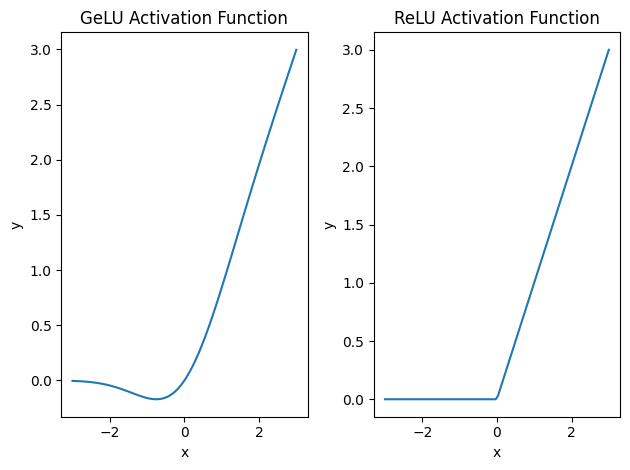

In [20]:
import matplotlib.pyplot as plt
gelu, relu = GeLU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)
y_gelu = gelu(x)
y_relu = relu(x)

for i, (y, label) in enumerate(zip([y_gelu, y_relu], ['GeLU', 'ReLU']), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} Activation Function")
    plt.xlabel('x')
    plt.ylabel('y')
plt.tight_layout()
plt.show()

- ReLU as seen is a piecewise linear function that outputs the input directly if positieve or else zero if negative 
- GeLU is a smooth, non linear function that approximates ReLU but with a non zero gradient for almost all negative values (except at approx x = -0.75)

with GeLU neurons that receive negative input can also contribute to the learning process , albeit to a lesser extent that positieve inputs

smoothness of GeLU can lead to a better optimation os properties dyring training as it allows for more nuanced adjustments to models parameters

### A feed forward neural network module 

In [21]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(config["embedding_dim"], 4 * config["embedding_dim"]),
            nn.GELU(),
            nn.Linear(4 * config["embedding_dim"], config["embedding_dim"])
        )
        
    def forward(self, x):
        return self.layers(x)

In [22]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.randn(2, 5, 768)
out = ffn(x)
out.shape
        


torch.Size([2, 5, 768])


The feed-forward network applies GELU in a wider space, then returns to the original width.

With `embedding_dim = 768` the two linear layers are `768 → 3072` and `3072 → 768`. `3072` is `4 * embedding_dim`.

The first layer turns each token's 768 numbers into 3072 learned features. GELU then runs on each of those 3072 numbers separately. Because GELU is nonlinear, the expand and the contract do not collapse into one linear layer: a feature can be mostly off without being cut to zero the way ReLU cuts it. The second layer mixes the 3072 features back down to 768, which is the width the residual stream expects, so the feed-forward output can be added to the token vector it started from.

Such a design allows for exploration of a richer representation of space

# Adding a shortcut connection

- also known as skip or residual connections
- was introduced for deep networks in computer vision to mitigate the problem of vanishing gradients
- vanishing gradients refer to the issue where gradients became progressively smaller as they propagate backward through the layers, making it difficult to effectively train earlier lauyers

- shortcut connection creates an alternative shorter path for the gradient to flow through the network by skipping one or more layers which is achieved by adding the output of one layer to the output of a later ;layer

### A neural network to illustrate shortcut connection

In [23]:
import  torch.nn as nn

class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(layer_sizes[0], layer_sizes[1]),
                GeLU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[1], layer_sizes[2]),
                GeLU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[2], layer_sizes[3]),
                GeLU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[3], layer_sizes[4]),
                GeLU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[4], layer_sizes[5]),
                GeLU()
            )
        ])
        
    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape  :
                x = x + layer_output
            else:
                x = layer_output
        return x
        

In [24]:
import torch 
layers_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(layers_sizes, use_shortcut=False)

In [25]:
def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()
    loss = loss(output, target)
    loss.backward()
    for name, param in model.named_parameters():
        if param.grad is not None:
            print(f"{name}: {param.grad.abs().mean().item()}")
            
            

In [26]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight: 0.00020173584925942123
layers.0.0.bias: 0.00030260378844104707
layers.1.0.weight: 0.00012011158833047375
layers.1.0.bias: 0.0008435298223048449
layers.2.0.weight: 0.0007152041071094573
layers.2.0.bias: 0.003959516528993845
layers.3.0.weight: 0.0013988735154271126
layers.3.0.bias: 0.012068115174770355
layers.4.0.weight: 0.005049645435065031
layers.4.0.bias: 0.0718674585223198


In [27]:
import torch 
layers_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(layers_sizes, use_shortcut=True)

In [28]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight: 0.22169791162014008
layers.0.0.bias: 0.3325468599796295
layers.1.0.weight: 0.20694106817245483
layers.1.0.bias: 0.2764998972415924
layers.2.0.weight: 0.32896992564201355
layers.2.0.bias: 0.43787992000579834
layers.3.0.weight: 0.2665732204914093
layers.3.0.bias: 0.27320900559425354
layers.4.0.weight: 1.3258540630340576
layers.4.0.bias: 1.632752537727356


# Transformer Blocks

![Transformer block](transformer-block.png)

In [35]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, num_heads, context_length, qkv_bias=False, dropout=0.5):
        super().__init__()

        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_in = d_in
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.Wq = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.Wk = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.Wv = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(p=dropout)
        self.out_proj = nn.Linear(d_out, d_out)
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        batch_size, number_of_tokens, d_in = x.shape # (b, t, c)

        queries = self.Wq(x)
        keys = self.Wk(x)
        values = self.Wv(x)

        queries = queries.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]
        keys = keys.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]
        values = values.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]

        queries = queries.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]
        keys = keys.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]
        values = values.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]

        attention_scores = queries @ keys.transpose(-2, -1) # [b,nh,t,hd] @ [b,nh,hd,t] -> [b,nh,t,t]

        attention_scores.masked_fill_(self.mask.bool()[:number_of_tokens, :number_of_tokens], float('-inf'))

        attention_weights = torch.softmax(attention_scores/ keys.shape[-1]**0.5, dim=-1)

        attention_weights = self.dropout(attention_weights)

        context_vector = attention_weights @ values

        context_vector = context_vector.transpose(1, 2) # [b,nh,t,hd] -> [b,t,nh,hd]
        context_vector = context_vector.contiguous().view(batch_size, number_of_tokens, self.d_out) # [b,t,nh,hd] -> [b,t,c]

        context_vector = self.out_proj(context_vector)

        return context_vector
        
class LayerNorm(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(embedding_dim))
        self.shift = nn.Parameter(torch.zeros(embedding_dim))
        
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        variance = x.var(dim=-1, keepdim=True, unbiased=False)
        normalized_x = (x - mean) / torch.sqrt(variance + self.eps)
        return self.scale * normalized_x + self.shift

class GeLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))

class FeedForward(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim),
            nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim)
        )
        
    def forward(self, x):
        return self.layers(x)    

In [36]:
class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.mha = MultiHeadAttention(
            d_in=config["embedding_dim"],
            d_out=config["embedding_dim"],
            num_heads=config["n_heads"],
            context_length=config["context_length"],
            qkv_bias=config["qkv_bias"],
            dropout=config["drop_rate"]
        )
        self.ln1 = LayerNorm(config["embedding_dim"])
        self.ln2 = LayerNorm(config["embedding_dim"])
        self.ffn = FeedForward(config["embedding_dim"])
        self.dropout = nn.Dropout(config["drop_rate"])

    def forward(self, x):

        #component 1: Multi-head attention
        ln1_out = self.ln1(x)
        mha_out = self.mha(ln1_out)
        dropout_1_out = self.dropout(mha_out)
        x = x + dropout_1_out # skip connection

        #component 2: Feed forward network
        ln2_out = self.ln2(x)
        ffn_out = self.ffn(ln2_out)
        dropout_2_out = self.dropout(ffn_out)
        x = x + dropout_2_out # skip connection

        return x
        

- Transformer block has two components
    - Multi head attention
    - Feed forward network

- Layer Norm is applied before each of the components and dropout after to regularize the model and prevent overfitting, known as Pre Layer Norm
- In older architectures Layer norm applied after atrtention and feedforward networks, known as Post Layer Norm, which often leads to worst training dynamics
- The class also implements forward pass,where each component is followed by a shortcut connection that adds the input of the block to its output. Critical to help gradients flow through the network during training and improves the learning of deep models

In [37]:
GPT_CONFIG_124M

{'vocab_size': 50257,
 'context_length': 1024,
 'embedding_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'drop_rate': 0.1,
 'qkv_dim': False}

In [40]:
torch.manual_seed(123)
batch_size = 2
context_length = 4
embedding_dim = 768

x = torch.randn(batch_size, context_length, embedding_dim)
block = TransformerBlock(GPT_CONFIG_124M)
out = block(x)

In [41]:
print(f"Input shape: {x.shape}")
print(f"Output shape: {out.shape}")

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


# Coding the GPT Model

In [42]:
class GPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.token_embedding = nn.Embedding(config["vocab_size"], config["embedding_dim"])
        self.positional_embedding = nn.Embedding(config["context_length"], config["embedding_dim"])
        self.dropout = nn.Dropout(config["drop_rate"])
        self.transformer_blocks = nn.Sequential(*[
            TransformerBlock(config) for _ in range(config["n_layers"])
        ])
        self.final_layer_norm = LayerNorm(config["embedding_dim"])
        self.out_head = nn.Linear(config["embedding_dim"], config["vocab_size"])
        
    def forward(self, x):
        batch_size, number_of_tokens = x.shape
        x = self.token_embedding(x) + self.positional_embedding(torch.arange(number_of_tokens, device=x.device))
        x = self.dropout(x)
        x = self.transformer_blocks(x)
        x = self.final_layer_norm(x)
        logits = self.out_head(x)
        return logits

In [43]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)


In [45]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []
text_1 = "Every effort moves you"
text_2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(text_1)))
batch.append(torch.tensor(tokenizer.encode(text_2)))

batch = torch.stack(batch)

batch

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

In [47]:
out = model(batch)

print(out)

tensor([[[-0.5758, -0.0533,  0.0185,  ...,  0.6056,  0.4055, -0.2961],
         [ 0.4220, -0.0617, -0.5883,  ...,  0.0497,  0.5532, -0.6850],
         [ 0.6290, -0.3393,  0.3465,  ...,  0.1792, -0.2102, -0.2376],
         [-0.8158,  0.1340, -0.2200,  ...,  1.3132,  0.4377, -0.2726]],

        [[ 0.3518,  0.5148,  0.1995,  ...,  0.4340,  0.1224, -0.4856],
         [ 0.5006,  0.0523,  0.0605,  ...,  0.5649,  0.2261,  0.2592],
         [ 0.8778,  0.8181, -0.1494,  ...,  0.7891, -0.1739, -0.1419],
         [-0.3446,  0.2529,  0.6076,  ...,  1.1087, -0.5113,  0.2637]]],
       grad_fn=<ViewBackward0>)


In [48]:
out.shape

torch.Size([2, 4, 50257])

In [52]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params}")


Total number of parameters: 163059793


weight tying

In [53]:
print("Token embedding layer shape: ", model.token_embedding.weight.shape)
print("Out head layer shape: ", model.out_head.weight.shape)

print("Token embedding layer and out head layer shapes match: ", model.token_embedding.weight.shape == model.out_head.weight.shape)




Token embedding layer shape:  torch.Size([50257, 768])
Out head layer shape:  torch.Size([50257, 768])
Token embedding layer and out head layer shapes match:  True


In [55]:
total_params_gpt2 = total_params -sum(p.numel() for p in model.out_head.parameters())
print(f"Total number of parameters in GPT-2: {total_params_gpt2}")


Total number of parameters in GPT-2: 124412160


Total number of parameters in the feed forward module: 56669184
Total number of parameters in the multi head attention module: 28320768


In [68]:
num_params_ffn = 0
for i, block in enumerate(model.transformer_blocks):
    for p in block.ffn.parameters():
        num_params_ffn += p.numel()
print(f"Total number of parameters in the feed forward module: {num_params_ffn/12}")

num_params_mha = 0
for i, block in enumerate(model.transformer_blocks):
    for p in block.mha.parameters():
        num_params_mha += p.numel()
print(f"Total number of parameters in the multi head attention module: {num_params_mha/12}")


Total number of parameters in the feed forward module: 4722432.0
Total number of parameters in the multi head attention module: 2360064.0


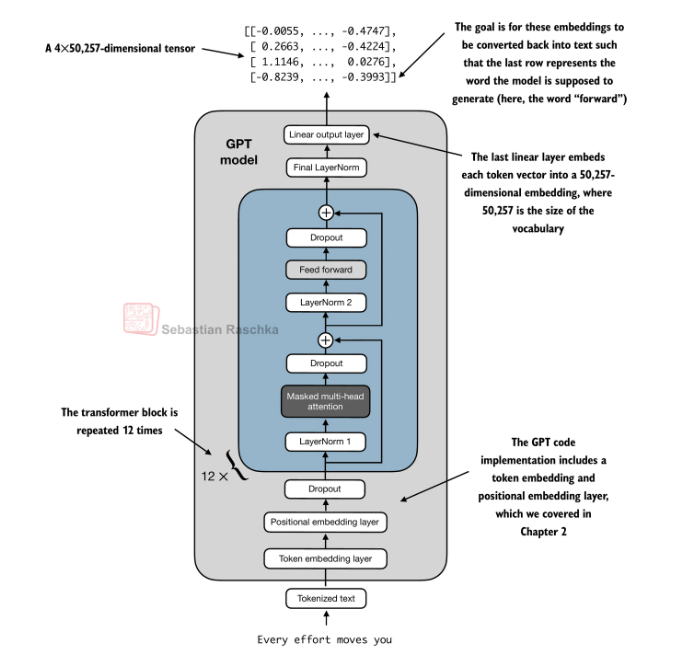

In [1]:
from IPython.display import Image, display
display(Image(filename="gpt-model.png"))


In [70]:
# memory requiements of a 163M param model

total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024 * 1024)
print(f"Total memory required: {total_size_mb} MB")

Total memory required: 622.0237464904785 MB


### GTM Medium initialize

In [72]:
GPT_CONFIG_MEDIUM = {
    "vocab_size": 50257,
    "context_length": 1024,
    "embedding_dim": 1024,
    "n_heads": 16,
    "n_layers": 24,
    "drop_rate": 0.0,
    "qkv_bias": False,
    
}

In [75]:
model = GPTModel(GPT_CONFIG_MEDIUM)
model_size_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {model_size_params/1000000}M parameters")

model_size_mb = model_size_params * 4 / (1024 * 1024 * 1024)
print(f"Model size: {model_size_mb} GB")

Model size: 406.262865M parameters
Model size: 1.5134471096098423 GB


In [76]:
GPT_CONFIG_LARGE = {
    "vocab_size": 50257,
    "context_length": 1024,
    "embedding_dim": 1280,
    "n_heads": 20,
    "n_layers": 36,
    "drop_rate": 0.0,
    "qkv_bias": False,
    
}

In [78]:
model = GPTModel(GPT_CONFIG_LARGE)
model_size_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {model_size_params/1000000}M parameters")

model_size_mb = model_size_params * 4 / (1024 * 1024 * 1024)
print(f"Model size: {model_size_mb} GB")

Model size: 838.271057M parameters
Model size: 3.122803036123514 GB


In [79]:
GPT_CONFIG_2XLARGE = {
    "vocab_size": 50257,
    "context_length": 1024,
    "embedding_dim": 1600,
    "n_heads": 25,
    "n_layers": 48,
    "drop_rate": 0.0,
    "qkv_bias": False,
    
}

In [80]:
model = GPTModel(GPT_CONFIG_2XLARGE)
model_size_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {model_size_params/1000000}M parameters")

model_size_mb = model_size_params * 4 / (1024 * 1024 * 1024)
print(f"Model size: {model_size_mb} GB")

Model size: 1637.842257M parameters
Model size: 6.101437870413065 GB


# Token Generation

In [ ]:
def generate_text(model, tokenizer, prompt, max_new_tokens=100):
    model.eval()
    tokens = tokenizer.encode(prompt)
    tokens = torch.tensor(tokens).unsqueeze(0) # add a batch dimension
    for _ in range(max_new_tokens):
        logits = model(tokens)
        probs = logits[:, -1, :] # focus only on the last token
        input_next_token = torch.argmax(probs, dim=-1, keepdim=True) # get the index of the most likely next token (highest probability)
        tokens = torch.cat((tokens, input_next_token), dim=-1)
    return tokens


In [90]:
model = GPTModel(GPT_CONFIG_124M)
tokenizer = tiktoken.get_encoding("gpt2")

prompt = "Hello, how are you?"
generated_tokens = generate_text(model, tokenizer, prompt, max_new_tokens=100)
print(generated_tokens)


tensor([[15496,    11,   703,   389,   345,    30,  1149, 19881, 28180, 13603,
         28092,  8060, 26693, 43669,  9184, 21214, 12429, 33292, 20940, 15950,
         28008, 42390, 24476, 30984, 36178, 11302,  4612, 23139, 45959, 40770,
         17764, 11198, 36373,  4700, 31937, 37285, 15801, 27413, 25392, 12626,
         10040, 22389, 32703,  6236, 50064, 46419,  8103, 27403, 18668, 35560,
         46718,  3243,   148,  8373, 10084,  9211,  5417, 33255, 41105, 42313,
         27272, 30969, 47081, 31092, 30235, 24517,   826,  2765, 34048, 42119,
          1831, 35573, 12393, 38407, 37188, 28089, 36009, 27720, 19537,  9446,
         14733, 48500, 27576, 42549,  3297, 38047, 28683, 35450, 41457, 30137,
         34058, 23459, 17006, 16608, 27863, 43804,  5735, 18367,  8104, 49322,
         19772, 24241, 12345, 45393, 38524, 43813]])


In [93]:
generated_text = tokenizer.decode(generated_tokens.squeeze(0).tolist())
print(generated_text)

Hello, how are you? charbf PLAYDevandro Global Paladinyeahapon Rut ** MiracleANC utterlySingle Daredevil wors diamonds Stoke Financialinct comedian 418 blister compatibility Double twisting Treexpr Petra106 compressLockspan diseases obey grazbur paternity vaccinationsaching Vader ancestors az fictitiousyond� frequency diverse deeper seahang Abandon 429 Limit Fathers Providesresourcerafted Identified rightlege Thou Bulgarianraw mosquitoesDay illuminate amplitudeorers adamant646oulosinterest humor Aden nec ailments sortadena Bunny Mayhem Hawth disparity Superintendent Tsuchat upgrades Conflict stopp tele Pv laidDeploy radi stumbledacre wastefulwashing antennas
